# Wi‑Fi Vision — baseline ثلاثي الأبعاد من CSI

هذا الدفتر ينزّل **عينة صغيرة فقط** من Wiception3D المرتبطة رسميًا بمشروع Person‑in‑WiFi 3D، يفحص CSI والوسوم `14×3`، يدرب baseline خفيفًا، ثم يقيس MPJPE.

النتيجة هنا اختبار هندسي صغير وليست إعادة إنتاج لنتيجة الورقة. مجموعة Wi‑Pose المنفصلة ثنائية الأبعاد ولا تُستخدم هنا لإثبات 3D.

## 1. الإعداد والتخزين المستمر

في Colab سيظهر طلب واحد لربط Google Drive. البيانات والنتائج تحفظ تحت `MyDrive/WiFiVision` كي لا تضيع بانتهاء الجلسة. خارج Colab يستخدم الدفتر مجلد المشروع الحالي.

In [1]:
import importlib.util, subprocess, sys, os
from pathlib import Path

required = {'requests':'requests>=2.31', 'h5py':'h5py>=3.10', 'sklearn':'scikit-learn>=1.4', 'joblib':'joblib>=1.3', 'matplotlib':'matplotlib>=3.8'}
missing = [pkg for mod, pkg in required.items() if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])

try:
    IN_COLAB = importlib.util.find_spec('google.colab') is not None
except ModuleNotFoundError:
    IN_COLAB = False
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    RUN_ROOT = Path('/content/drive/MyDrive/WiFiVision')
else:
    RUN_ROOT = Path.cwd()
RUN_ROOT.mkdir(parents=True, exist_ok=True)
DATA_ROOT = RUN_ROOT / 'data/wiception3d_small'
OUTPUT_ROOT = RUN_ROOT / 'artifacts/notebook_run'
print({'in_colab': IN_COLAB, 'run_root': str(RUN_ROOT)})

{'in_colab': False, 'run_root': '/workspace/wifi-vision/notebooks'}


## 2. تنزيل محدود وقابل للاستئناف

نستخدم ملفات منفردة من المصدر بدل تنزيل الأرشيف الكامل (نحو 18.7 GB). الملف المكتمل والصالح لا يُنزّل ثانية، والجزئي يُستأنف عندما يدعم الخادم طلبات النطاق.

In [2]:
#!/usr/bin/env python3
from __future__ import annotations

import argparse
import hashlib
import json
import os
import threading
import time
import random
from concurrent.futures import ThreadPoolExecutor, as_completed
from pathlib import Path
from urllib.parse import quote

import h5py
import numpy as np
import requests


DATASET = "xjtuqianbo/wiception3d"
VERSION = 1
BASE = "https://www.kaggle.com/api/v1/datasets/download"
LIST_PATHS = {
    "train": "wifi_dataset/train_data/train_data_list.txt",
    "test": "wifi_dataset/test_data/test_data_list.txt",
}
THREAD_LOCAL = threading.local()


def session() -> requests.Session:
    if not hasattr(THREAD_LOCAL, "session"):
        THREAD_LOCAL.session = requests.Session()
        THREAD_LOCAL.session.headers["User-Agent"] = "wifi-vision-research/0.1"
    return THREAD_LOCAL.session


def sha256(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def valid_file(path: Path, remote_path: str) -> bool:
    if not path.exists() or path.stat().st_size == 0:
        return False
    try:
        if remote_path.endswith(".npy"):
            value = np.load(path, mmap_mode="r")
            return value.ndim == 3 and value.shape[1:] == (14, 3)
        if remote_path.endswith(".mat"):
            with h5py.File(path, "r") as handle:
                return handle["csi_out"].shape == (20, 30, 3, 3)
        if remote_path.endswith(".txt"):
            return bool(path.read_text(encoding="utf-8").strip())
    except Exception:
        return False
    return True


def download(remote_path: str, destination: Path, retries: int = 9) -> Path:
    destination.parent.mkdir(parents=True, exist_ok=True)
    if valid_file(destination, remote_path):
        return destination
    partial = destination.with_suffix(destination.suffix + ".part")
    url = f"{BASE}/{DATASET}/{quote(remote_path, safe='')}?datasetVersionNumber={VERSION}"
    for attempt in range(retries):
        start = partial.stat().st_size if partial.exists() else 0
        headers = {"Range": f"bytes={start}-"} if start else {}
        try:
            response = session().get(url, headers=headers, stream=True, timeout=(20, 90))
            if response.status_code == 429:
                retry_after = float(response.headers.get("Retry-After", "0") or 0)
                raise requests.HTTPError(
                    f"rate limited; retry_after={retry_after}", response=response
                )
            response.raise_for_status()
            append = start > 0 and response.status_code == 206
            if not append:
                start = 0
            mode = "ab" if append else "wb"
            with partial.open(mode) as handle:
                for chunk in response.iter_content(128 * 1024):
                    if chunk:
                        handle.write(chunk)
            expected_tail = int(response.headers.get("content-length", "0"))
            if expected_tail and partial.stat().st_size != start + expected_tail:
                raise IOError("downloaded size does not match Content-Length")
            if not valid_file(partial, remote_path):
                raise IOError("downloaded file failed format/shape validation")
            os.replace(partial, destination)
            return destination
        except Exception as error:
            if attempt + 1 == retries:
                raise
            retry_after = 0.0
            if isinstance(error, requests.HTTPError) and error.response is not None:
                retry_after = float(error.response.headers.get("Retry-After", "0") or 0)
            delay = max(retry_after, min(60.0, 2.0 ** attempt)) + random.uniform(0.0, 1.0)
            time.sleep(delay)
    raise RuntimeError(f"unreachable: failed to download {remote_path}")


def spread_selection(names: list[str], prefix: str, count: int) -> list[str]:
    """Round-robin across clip IDs so a tiny sample is not one contiguous moment."""
    groups: dict[str, list[str]] = {}
    for name in names:
        if not name.startswith(prefix + "_"):
            continue
        parts = name.split("_")
        groups.setdefault(parts[1], []).append(name)
    for values in groups.values():
        values.sort(key=lambda x: int(x.rsplit("_", 1)[-1]))
    selected: list[str] = []
    while len(selected) < count and any(groups.values()):
        for key in sorted(groups, key=lambda x: int(x)):
            if groups[key] and len(selected) < count:
                index = len(groups[key]) // 2
                selected.append(groups[key].pop(index))
    if len(selected) < count:
        raise ValueError(f"Only found {len(selected)} samples for {prefix}; requested {count}")
    return selected


def download_many(tasks: list[tuple[str, Path]], workers: int) -> list[Path]:
    results: list[Path] = []
    with ThreadPoolExecutor(max_workers=workers) as executor:
        futures = {executor.submit(download, remote, local): remote for remote, local in tasks}
        for index, future in enumerate(as_completed(futures), start=1):
            results.append(future.result())
            if index % 50 == 0 or index == len(tasks):
                print(f"  downloaded/validated {index}/{len(tasks)} files", flush=True)
    return results


def build_sample(root: Path, samples_per_group: int, workers: int) -> Path:
    lists_dir = root / "lists"
    for split, remote in LIST_PATHS.items():
        download(remote, lists_dir / f"{split}_data_list.txt")
    names = {
        split: [x for x in (lists_dir / f"{split}_data_list.txt").read_text().splitlines() if x]
        for split in LIST_PATHS
    }
    plan = [
        ("train", "S11", spread_selection(names["train"], "S11", samples_per_group)),
        ("train", "S21", spread_selection(names["train"], "S21", samples_per_group)),
        ("test", "S11", spread_selection(names["test"], "S11", samples_per_group)),
        ("test", "S21", spread_selection(names["test"], "S21", samples_per_group)),
        ("test", "S51", spread_selection(names["test"], "S51", samples_per_group)),
    ]

    label_tasks: list[tuple[str, Path]] = []
    for split, group, sample_ids in plan:
        for sample_id in sample_ids:
            remote = f"wifi_dataset/{split}_data/keypoint/{sample_id}.npy"
            label_tasks.append((remote, root / split / "keypoint" / f"{sample_id}.npy"))
    print(f"Downloading labels for {len(label_tasks)} planned samples...")
    download_many(label_tasks, workers)

    accepted: list[tuple[str, str, str, Path]] = []
    for split, group, sample_ids in plan:
        for sample_id in sample_ids:
            pose_path = root / split / "keypoint" / f"{sample_id}.npy"
            if np.load(pose_path, mmap_mode="r").shape == (1, 14, 3):
                accepted.append((split, group, sample_id, pose_path))
    if len(accepted) != 5 * samples_per_group:
        raise ValueError("Some planned samples were not single-person frames")

    csi_tasks: list[tuple[str, Path]] = []
    for split, _group, sample_id, _pose in accepted:
        remote = f"wifi_dataset/{split}_data/csi/{sample_id}.mat"
        csi_tasks.append((remote, root / split / "csi" / f"{sample_id}.mat"))
    print(f"Downloading CSI for {len(csi_tasks)} accepted samples...")
    download_many(csi_tasks, workers)

    records = []
    for split, group, sample_id, pose_path in accepted:
        csi_path = root / split / "csi" / f"{sample_id}.mat"
        records.append({
            "sample_id": sample_id,
            "split": split,
            "capture_group": group,
            "csi_path": str(csi_path.resolve()),
            "pose_path": str(pose_path.resolve()),
            "csi_bytes": csi_path.stat().st_size,
            "pose_bytes": pose_path.stat().st_size,
            "csi_sha256": sha256(csi_path),
            "pose_sha256": sha256(pose_path),
        })
    manifest = {
        "source": "https://www.kaggle.com/datasets/xjtuqianbo/wiception3d",
        "source_project": "https://aiotgroup.github.io/Person-in-WiFi-3D/",
        "dataset_version": VERSION,
        "selection": (
            "S11 and S21 train plus temporal test frames; S51 held-out capture group; "
            "one-person frames only"
        ),
        "resume_behavior": "valid completed files are skipped; .part files resume when the server returns HTTP 206",
        "samples": records,
    }
    manifest_path = root / "manifest.json"
    manifest_path.write_text(json.dumps(manifest, indent=2), encoding="utf-8")
    print(f"Manifest: {manifest_path} ({len(records)} samples)")
    return manifest_path


def main() -> None:
    parser = argparse.ArgumentParser()
    parser.add_argument("--root", type=Path, default=Path("data/wiception3d_small"))
    parser.add_argument("--samples-per-group", type=int, default=50)
    parser.add_argument("--workers", type=int, default=4)
    args = parser.parse_args()
    build_sample(args.root.resolve(), args.samples_per_group, args.workers)



In [3]:
manifest_path = build_sample(DATA_ROOT, samples_per_group=50, workers=4)
manifest_path

  downloaded/validated 50/250 files


  downloaded/validated 100/250 files


  downloaded/validated 150/250 files


  downloaded/validated 200/250 files


  downloaded/validated 250/250 files


  downloaded/validated 50/250 files


... (2 outputs left out)

  downloaded/validated 200/250 files


  downloaded/validated 250/250 files


Manifest: /workspace/wifi-vision/notebooks/data/wiception3d_small/manifest.json (250 samples)


PosixPath('/workspace/wifi-vision/notebooks/data/wiception3d_small/manifest.json')

## 3. فحص CSI والوسوم ثلاثية الأبعاد

In [4]:
from __future__ import annotations

import hashlib
import json
from pathlib import Path
from typing import Iterable

import h5py
import joblib
import matplotlib.pyplot as plt
import numpy as np
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


# Order evidenced by Table 2 of the Person-in-WiFi 3D paper and root=[5,7] in its code.
JOINT_NAMES = [
    "neck", "head", "L shoulder", "R shoulder", "L elbow", "L hip",
    "R elbow", "R hip", "L hand", "L knee", "R hand", "R knee", "L ankle", "R ankle",
]
SKELETON_EDGES = [
    (0, 1), (0, 2), (2, 4), (4, 8), (0, 3), (3, 6), (6, 10),
    (2, 5), (3, 7), (5, 7), (5, 9), (9, 12), (7, 11), (11, 13),
]


def sha256_file(path: str | Path, chunk_size: int = 1024 * 1024) -> str:
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()


def load_complex_csi(path: str | Path) -> np.ndarray:
    """Load Person-in-WiFi 3D HDF5 MATLAB CSI as complex [time, subcarrier, tx, rx]."""
    with h5py.File(path, "r") as handle:
        raw = handle["csi_out"][()]
    if raw.dtype.fields and {"real", "imag"}.issubset(raw.dtype.fields):
        csi = raw["real"] + 1j * raw["imag"]
    else:
        csi = np.asarray(raw, dtype=np.complex128)
    if csi.ndim != 4:
        raise ValueError(f"Expected 4D CSI, got {csi.shape} from {path}")
    return csi


def load_single_person_pose(path: str | Path) -> np.ndarray:
    pose = np.asarray(np.load(path), dtype=np.float64)
    if pose.shape != (1, 14, 3):
        raise ValueError(f"Expected one-person pose [1,14,3], got {pose.shape} from {path}")
    return pose[0]


def csi_features(csi: np.ndarray) -> np.ndarray:
    """Compact amplitude/phase moments; avoids keeping raw frames in RAM."""
    amplitude = np.log1p(np.abs(csi))
    phase = np.unwrap(np.angle(csi), axis=0)
    phase_delta = np.diff(phase, axis=0)
    blocks = [
        amplitude.mean(axis=0),
        amplitude.std(axis=0),
        np.cos(phase_delta).mean(axis=0),
        np.sin(phase_delta).mean(axis=0),
        phase_delta.std(axis=0),
    ]
    features = np.concatenate([block.ravel() for block in blocks]).astype(np.float32)
    if not np.isfinite(features).all():
        raise ValueError("CSI feature vector contains NaN or infinity")
    return features


def load_manifest_dataset(manifest_path: str | Path) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    manifest_path = Path(manifest_path)
    records = json.loads(manifest_path.read_text(encoding="utf-8"))["samples"]
    features, poses, splits, groups = [], [], [], []
    for record in records:
        features.append(csi_features(load_complex_csi(record["csi_path"])))
        poses.append(load_single_person_pose(record["pose_path"]))
        splits.append(record["split"])
        groups.append(record["capture_group"])
    return (
        np.stack(features),
        np.stack(poses),
        np.asarray(splits),
        np.asarray(groups),
    )


def mpjpe_mm(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    return float(np.linalg.norm(y_true - y_pred, axis=-1).mean() * 1000.0)


def root_relative(poses: np.ndarray) -> np.ndarray:
    mid_hip = poses[:, [5, 7]].mean(axis=1, keepdims=True)
    return poses - mid_hip


def per_joint_error_mm(y_true: np.ndarray, y_pred: np.ndarray) -> np.ndarray:
    return np.linalg.norm(y_true - y_pred, axis=-1).mean(axis=0) * 1000.0


def train_ridge_baseline(
    x_train: np.ndarray,
    y_train: np.ndarray,
    max_components: int = 64,
    alpha: float = 20.0,
) -> Pipeline:
    components = max(2, min(max_components, x_train.shape[0] - 1, x_train.shape[1]))
    model = Pipeline([
        ("scale", StandardScaler()),
        ("pca", PCA(n_components=components, whiten=True, random_state=42)),
        ("ridge", Ridge(alpha=alpha)),
    ])
    model.fit(x_train, y_train.reshape(len(y_train), -1))
    return model


def evaluate_and_save(
    manifest_path: str | Path,
    output_dir: str | Path,
    max_components: int = 64,
    alpha: float = 20.0,
) -> dict:
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    x, y, split, groups = load_manifest_dataset(manifest_path)
    train_mask = split == "train"
    in_domain_mask = (split == "test") & np.isin(groups, ["S11", "S21"])
    heldout_mask = (split == "test") & (groups == "S51")
    if train_mask.sum() < 2 or in_domain_mask.sum() < 1 or heldout_mask.sum() < 1:
        raise ValueError("Manifest needs at least 2 train and 1 test samples")

    model = train_ridge_baseline(x[train_mask], y[train_mask], max_components, alpha)
    train_mean = y[train_mask].mean(axis=0)

    def score(mask: np.ndarray) -> tuple[dict, np.ndarray, np.ndarray]:
        pred = model.predict(x[mask]).reshape(-1, 14, 3)
        truth = y[mask]
        mean_pose = np.broadcast_to(train_mean, truth.shape)
        result = {
            "n": int(mask.sum()),
            "groups": sorted(np.unique(groups[mask]).tolist()),
            "ridge_mpjpe_mm": mpjpe_mm(truth, pred),
            "mean_pose_mpjpe_mm": mpjpe_mm(truth, mean_pose),
            "ridge_root_relative_mpjpe_mm": mpjpe_mm(root_relative(truth), root_relative(pred)),
            "mean_pose_root_relative_mpjpe_mm": mpjpe_mm(root_relative(truth), root_relative(mean_pose)),
        }
        return result, truth, pred

    in_domain, in_truth, in_pred = score(in_domain_mask)
    heldout, heldout_truth, heldout_pred = score(heldout_mask)

    metrics = {
        "task": "single-person absolute 3D joint regression",
        "split": "S11+S21 train; temporal in-domain test on S11+S21; capture-group holdout on S51",
        "n_train": int(train_mask.sum()),
        "n_features": int(x.shape[1]),
        "capture_groups_train": sorted(np.unique(groups[train_mask]).tolist()),
        "in_domain_temporal": in_domain,
        "heldout_capture_group": heldout,
        "per_joint_error_mm": dict(
            zip(JOINT_NAMES, per_joint_error_mm(heldout_truth, heldout_pred).round(3).tolist())
        ),
        "important_limit": (
            "This is a tiny engineering baseline on a capture-group holdout, not a reproduction "
            "of the paper and not a subject-disjoint benchmark."
        ),
    }
    (output_dir / "metrics.json").write_text(
        json.dumps(metrics, indent=2, ensure_ascii=False), encoding="utf-8"
    )
    joblib.dump(model, output_dir / "ridge_3d_baseline.joblib")
    np.savez_compressed(
        output_dir / "test_predictions.npz",
        in_domain_truth=in_truth,
        in_domain_prediction=in_pred,
        heldout_truth=heldout_truth,
        heldout_prediction=heldout_pred,
    )
    return metrics


def plot_csi_and_pose(
    csi: np.ndarray,
    truth: np.ndarray,
    prediction: np.ndarray | None,
    output_path: str | Path,
) -> None:
    fig = plt.figure(figsize=(12, 5), constrained_layout=True)
    ax1 = fig.add_subplot(1, 2, 1)
    heat = np.log1p(np.abs(csi[:, :, 0, 0])).T
    image = ax1.imshow(heat, aspect="auto", origin="lower", cmap="viridis")
    ax1.set_title("CSI amplitude: one Tx/Rx pair")
    ax1.set_xlabel("Packet in 20-sample window")
    ax1.set_ylabel("Subcarrier (30)")
    fig.colorbar(image, ax=ax1, label="log(1 + amplitude)")

    ax2 = fig.add_subplot(1, 2, 2, projection="3d")
    for pose, label, color, style in [
        (truth, "Ground truth", "#0072B2", "-"),
        (prediction, "Ridge prediction", "#D55E00", "--"),
    ]:
        if pose is None:
            continue
        ax2.scatter(pose[:, 0], pose[:, 2], pose[:, 1], s=22, color=color, label=label)
        for a, b in SKELETON_EDGES:
            ax2.plot(
                pose[[a, b], 0], pose[[a, b], 2], pose[[a, b], 1],
                color=color, linestyle=style, linewidth=1.5,
            )
    ax2.set_title("3D skeleton (actual coordinates)")
    ax2.set_xlabel("Horizontal (m)")
    ax2.set_ylabel("Depth (m)")
    ax2.set_zlabel("Vertical (m)")
    ax2.legend(loc="upper left")
    fig.savefig(output_path, dpi=160)
    plt.close(fig)


def plot_joint_errors(metrics: dict, output_path: str | Path) -> None:
    names = list(metrics["per_joint_error_mm"])
    values = [metrics["per_joint_error_mm"][name] for name in names]
    fig, ax = plt.subplots(figsize=(10, 4.8), constrained_layout=True)
    ax.bar(np.arange(len(names)), values, color="#0072B2")
    ax.set_xticks(np.arange(len(names)), names, rotation=45, ha="right")
    ax.set_ylabel("Mean Euclidean error (mm)")
    ax.set_title("Held-out capture-group error by joint")
    ax.grid(axis="y", alpha=0.25)
    fig.savefig(output_path, dpi=160)
    plt.close(fig)



In [5]:
import json
manifest = json.loads(manifest_path.read_text())['samples']
row = manifest[0]
sample_csi = load_complex_csi(row['csi_path'])
sample_pose = load_single_person_pose(row['pose_path'])
print('CSI shape:', sample_csi.shape, sample_csi.dtype)
print('Pose shape:', sample_pose.shape, sample_pose.dtype)
print('Feature length:', csi_features(sample_csi).shape[0])

CSI shape: (20, 30, 3, 3) complex128
Pose shape: (14, 3) float64
Feature length: 1350


## 4. تدريب baseline وتقييمه

التدريب على مجموعتي الالتقاط S11 وS21. نقيس اختبارًا زمنيًا من المجموعتين نفسيهما، ثم اختبار نقل أصعب على S51 المحجوزة بالكامل. المقياس MPJPE بالملليمتر.

In [6]:
metrics = evaluate_and_save(manifest_path, OUTPUT_ROOT, max_components=64, alpha=20.0)
print(json.dumps(metrics, indent=2, ensure_ascii=False))

{
  "task": "single-person absolute 3D joint regression",
  "split": "S11+S21 train; temporal in-domain test on S11+S21; capture-group holdout on S51",
  "n_train": 100,
  "n_features": 1350,
  "capture_groups_train": [
    "S11",
    "S21"
  ],
  "in_domain_temporal": {
    "n": 100,
    "groups": [
      "S11",
      "S21"
    ],
    "ridge_mpjpe_mm": 879.2723852990772,
    "mean_pose_mpjpe_mm": 927.9954036890443,
    "ridge_root_relative_mpjpe_mm": 176.80810514878834,
    "mean_pose_root_relative_mpjpe_mm": 143.84076608929206
  },
  "heldout_capture_group": {
    "n": 50,
    "groups": [
      "S51"
    ],
    "ridge_mpjpe_mm": 1365.6700435372263,
    "mean_pose_mpjpe_mm": 994.4996939102209,
    "ridge_root_relative_mpjpe_mm": 268.45630647181787,
    "mean_pose_root_relative_mpjpe_mm": 156.43627946660084
  },
  "per_joint_error_mm": {
    "neck": 1372.227,
    "head": 1375.35,
    "L shoulder": 1383.199,
    "R shoulder": 1347.998,
    "L elbow": 1371.548,
    "L hip": 1333.665,
   

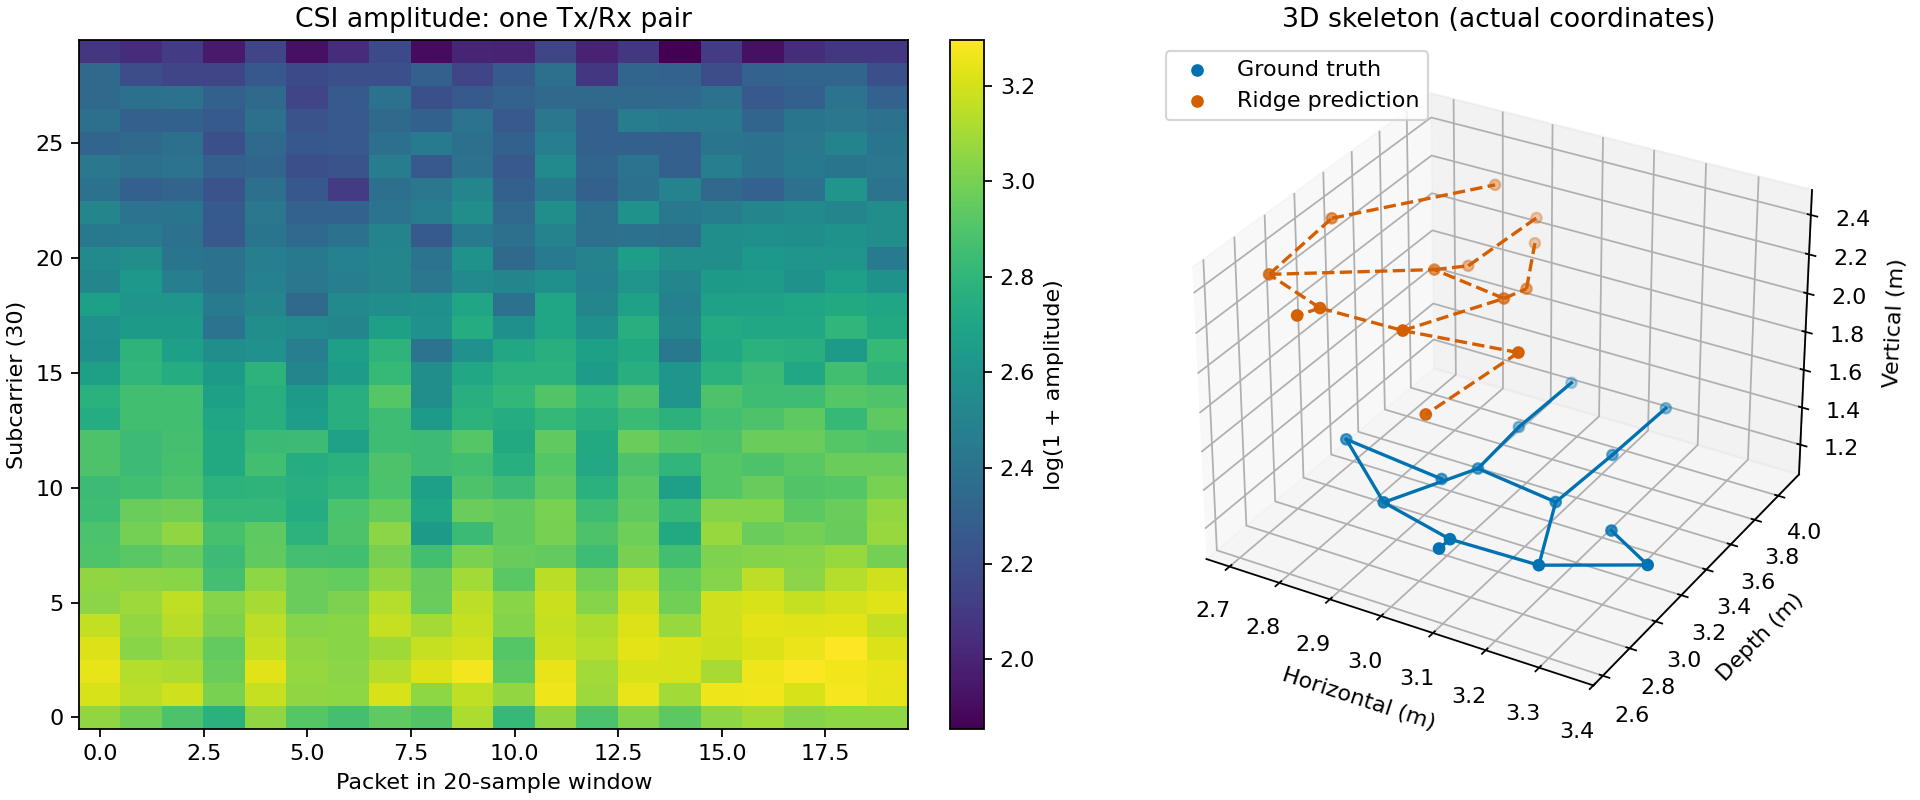

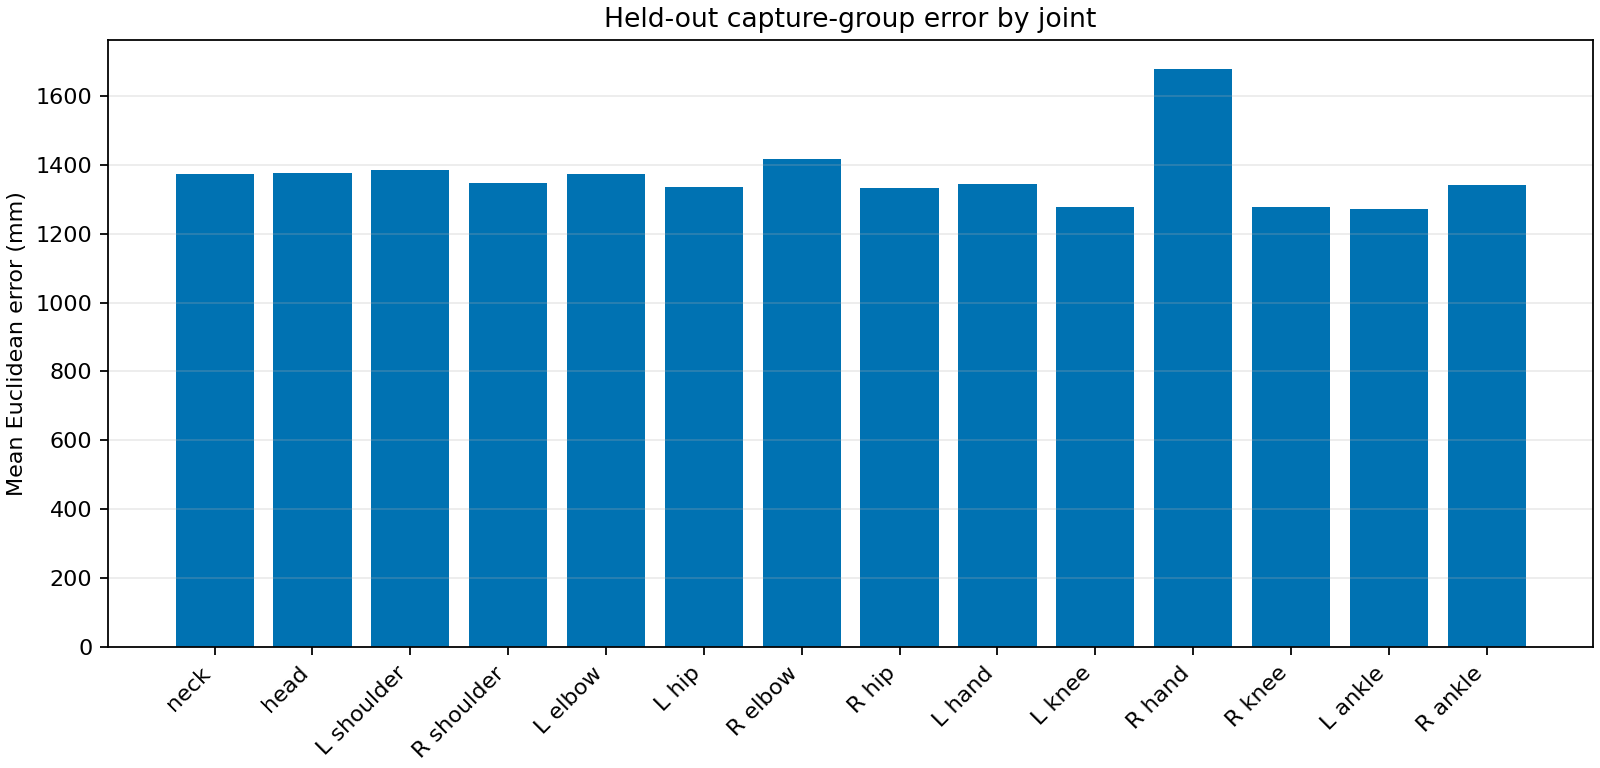

In [7]:
pred = np.load(OUTPUT_ROOT / 'test_predictions.npz')
heldout_row = next(r for r in manifest if r['split']=='test' and r['capture_group']=='S51')
plot_csi_and_pose(
    load_complex_csi(heldout_row['csi_path']),
    load_single_person_pose(heldout_row['pose_path']),
    pred['heldout_prediction'][0],
    OUTPUT_ROOT / 'csi_and_pose.png',
)
plot_joint_errors(metrics, OUTPUT_ROOT / 'joint_errors.png')
from IPython.display import display, Image
display(Image(filename=str(OUTPUT_ROOT / 'csi_and_pose.png')))
display(Image(filename=str(OUTPUT_ROOT / 'joint_errors.png')))

## 5. ما الذي تثبته التجربة وما الذي لا تثبته؟

- تثبت أن خط البيانات يعمل فعليًا من CSI مركب إلى إحداثيات مفاصل 3D ومقياس MPJPE.
- لا تثبت جودة عملية بعد؛ العينة صغيرة وRidge أبسط كثيرًا من Transformer الأصلي.
- هوية المتطوع غير موجودة في قوائم الملفات العامة المستخدمة هنا، لذلك هذا ليس تقسيمًا حسب الأشخاص.
- الفرق الكبير عند حجز S51 يوضح حساسية CSI لتغير مجموعة الالتقاط/البيئة.
- الخطوة التالية الجادة هي MM‑Fi بتقسيم `cross_subject_split` أو Wiception3D كاملة مع metadata للهوية.